# UTS GRAF SAINS DATA



- Nama  : Gesang Nur Zamroji
- NIM   : 23031554145 
- Kelas : 2023 D

# 1. Tugas Pendahuluan


## 1.1 Persiapan dan Perkenalan Lingkungan



Pada tahap persiapan, saya membuat  virtual environment `myenv`dengan versi Python 3.10.7

Selanjutnya Install dependensi paket-paket yang ada di dalam file `requirements.txt`

## 1.2 Mempelajari Penggunaan Driver Neo4J

Mendefinisikan string koneksi ke database Neo4J

In [2]:
from neo4j import GraphDatabase, RoutingControl
from getpass import getpass

PASSWORD = getpass("Masukkan password Neo4j: ")
URI = "neo4j://localhost:7687"
AUTH = ("neo4j", PASSWORD)

Fungsi `add_friend` berfungsi melakukan pembuatan sebuah Node `Person` berikut dengan relationship-nya `KNOWS`.

In [ ]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name,
        friend_name=friend_name,
        database_="neo4j",
    )
    
# MERGE mencari pola yang cocok; jika tidak ditemukan, pola tersebut akan dibuat.
# (a:Person {...}) menyatakan sebuah Node yang diberi label Person dan variabel query a.
# name adalah nama properti Node.
# $name adalah parameter yang nilainya dikirim dari Python.

Fungsi `print_friends` berfungsi melakukan pencarian relationship teman, dan  mengembalikan namanya

In [ ]:
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) " # Berbeda dari MERGE, MATCH hanya mencari pola yang sudah ada;  tidak membuat pola baru.
        "WHERE a.name = $name " # mepersemfit atau filter dengan name yang diinpitkan
        "RETURN friend.name ORDER BY friend.name", # dikembalikan dan di urutkan  
        name=name,
        database_="neo4j",
        routing_=RoutingControl.READ,
    )

    for record in records:
        print(record["friend.name"])
   

Dilanjutkan dengan pembuatan koneksi ke database `neo4j`

In [6]:
with GraphDatabase.driver(URI, auth=AUTH,database="neo4j") as driver:
    driver.verify_connectivity()

    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")


Guinevere
Lancelot
Merlin


### Pertanyaan Pendahuluan (Checkpoint)

#### 1. Apa nama database yang digunakan pada tutorial ini?

Database yang digunakan adalah `neo4j`.
ditunjukkan oleh parameter `database_="neo4j"` pada
Python Driver.

#### 2. Sebutkan akses lain yang dapat digunakan untuk mengakses database lain dalam satu instance!

- Database dalam satu instance Neo4j dapat diperiksa
menggunakan perintah Cypher `SHOW DATABASES`.

- Untuk menjalankan query pada database tertentu,
dapat digunakan klausa `USE nama_database`.
Selain itu, melalui Python Driver, database tujuan
dapat ditentukan menggunakan parameter `database_`.


#### 3. Apa jenis graf pertemanan yang telah dibuat?

Graf pertemanan yang dibuat termasuk directed
property graph atau graf properti berarah.

Graf tersebut memiliki node berlabel `Person`
dengan relationship bertipe `KNOWS`. Arah
relationship dimulai dari Arthur menuju Guinevere,
Lancelot, dan Merlin.


## 1.3 Melakukan Proses Impor Data RetailRocket ke Neo4j


Unduh RetailRocket E-commerce Dataset
yang diperoleh dari Kaggle  perintah berikut : 

In [ ]:
# curl.exe-L-o ecommerce-dataset.zip`
# https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset

Pada tahap awal, saya melakukan pemeriksaan struktur
dataset dan rentang waktu interaksi sebelum melakukan
filtering P1 P2 dan impor data ke Neo4j.

In [ ]:

import pandas as pd
from pathlib import Path

calon_path = [
    Path("../data/events.csv"),
    Path("data/events.csv")
]

csv_path = next(
    (p.resolve() for p in calon_path if p.is_file()),
    None
)

if csv_path is None:
    raise FileNotFoundError(
        "events.csv belum ditemukan di folder data/raw"
    )

print("Lokasi dataset:", csv_path)

df_preview = pd.read_csv(csv_path, nrows=5)

display(df_preview)


Lokasi dataset: D:\KULIAH SAINS DATA\SEMESTER 7\Graf Sada\UTS-GRAF\data\events.csv


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [15]:

# Pemeriksaan rentang waktu dan distribusi interaksi
# Membaca secara bertahap agar tidak boros memori

total_baris = 0
tanggal_awal = None
tanggal_akhir = None
jumlah_per_bulan = {}

for chunk in pd.read_csv(
    csv_path,
    usecols=["timestamp"],
    chunksize=100000
):
    total_baris += len(chunk)

    waktu = pd.to_datetime(
        chunk["timestamp"],
        unit="ms",
        utc=True,
        errors="coerce"
    )

    waktu_valid = waktu.dropna()

    if not waktu_valid.empty:
        awal_chunk = waktu_valid.min()
        akhir_chunk = waktu_valid.max()

        tanggal_awal = (
            awal_chunk if tanggal_awal is None
            else min(tanggal_awal, awal_chunk)
        )

        tanggal_akhir = (
            akhir_chunk if tanggal_akhir is None
            else max(tanggal_akhir, akhir_chunk)
        )

    hitungan = waktu.dt.strftime("%Y-%m").value_counts()

    for bulan, jumlah in hitungan.items():
        jumlah_per_bulan[bulan] = (
            jumlah_per_bulan.get(bulan, 0) + jumlah
        )

print("Total baris:", total_baris)
print("Tanggal awal:", tanggal_awal)
print("Tanggal akhir:", tanggal_akhir)

print("\nJumlah interaksi per bulan:")
display(
    pd.Series(jumlah_per_bulan)
    .sort_index()
    .rename("jumlah_interaksi")
    .to_frame()
)


Total baris: 2756101
Tanggal awal: 2015-05-03 03:00:04.384000+00:00
Tanggal akhir: 2015-09-18 02:59:47.788000+00:00

Jumlah interaksi per bulan:


,jumlah_interaksi
2015-05,590652
2015-06,610393
2015-07,697984
2015-08,553362
2015-09,303710


# 2. Soal UTS


### 2.1 Wrangling dan EDA




#### 2.1 - No 1 Penentuan Periode Training dan Testing

Dataset RetailRocket yang digunakan memiliki 2.756.101
baris interaksi, dengan rentang waktu 3 Mei 2015
hingga 18 September 2015.

Data dibagi menjadi dua periode berdasarkan timestamp:

- P1 (Training): 25 Juli 2015 - 7 Agustus 2015 (14 hari)
- P2 (Testing): 8 Agustus 2015 - 14 Agustus 2015 (7 hari)



In [23]:
# Menentukan periode berdasarkan batas waktu 
P1_START = "2015-07-25"
P1_END = "2015-08-08"  

P2_START = P1_END
P2_END = "2015-08-15"  


#### 2.1 - No 2 Filtering Timestamp dan Penyimpanan Dataset CSV

Setelah menentukan periode P1 dan P2, tahap berikutnya
adalah melakukan filtering data interaksi berdasarkan
timestamp.

Hasil filtering disimpan menjadi tiga file:

- train_P1.csv untuk data training.
- test_P2.csv untuk data testing.
- events_filtered.csv untuk gabungan kedua periode.

Pemisahan ini bertujuan agar data training dan testing
dapat dibedakan saat membangun serta mengevaluasi
sistem rekomendasi.

In [ ]:

import pandas as pd
from pathlib import Path


def to_milliseconds(date_str):
    return pd.Timestamp(
        date_str, tz="UTC"
    ).value // 1_000_000

p1_start = to_milliseconds(P1_START)
p1_end = to_milliseconds(P1_END)
p2_start = to_milliseconds(P2_START)
p2_end = to_milliseconds(P2_END)

assert p1_end <= p2_start, "P1 dan P2 tumpang tindih!"

project_dir = csv_path.parent.parent.parent
output_dir = Path.cwd() / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)
file_p1 = output_dir / "train_P1.csv"
file_p2 = output_dir / "test_P2.csv"
file_gabungan = output_dir / "events_filtered.csv"

files = {
    "P1": file_p1,
    "P2": file_p2,
}

kolom = [
    "timestamp",
    "visitorid",
    "event",
    "itemid",
    "transactionid",
    "periode"
]

for path in [file_p1, file_p2, file_gabungan]:
    path.write_text(
        ",".join(kolom) + "\n",
        encoding="utf-8"
    )

jumlah = {"P1": 0, "P2": 0}

for chunk in pd.read_csv(
    csv_path,
    chunksize=100000,
    dtype={"transactionid": "Int64"}
):
    mask_p1 = (
        (chunk["timestamp"] >= p1_start) &
        (chunk["timestamp"] < p1_end)
    )

    mask_p2 = (
        (chunk["timestamp"] >= p2_start) &
        (chunk["timestamp"] < p2_end)
    )

    for label, mask in [
        ("P1", mask_p1),
        ("P2", mask_p2)
    ]:
        data_filter = chunk.loc[mask].copy()
        data_filter["periode"] = label

        if data_filter.empty:
            continue

        data_filter.to_csv(
            files[label],
            mode="a",
            index=False,
            header=False
        )

        data_filter.to_csv(
            file_gabungan,
            mode="a",
            index=False,
            header=False
        )

        jumlah[label] += len(data_filter)

print("Filtering selesai!")
print("Jumlah data P1:", jumlah["P1"])
print("Jumlah data P2:", jumlah["P2"])
print("Total data terfilter:", sum(jumlah.values()))

print("\nFile disimpan pada:", output_dir)


Filtering selesai!
Jumlah data P1: 306731
Jumlah data P2: 118822
Total data terfilter: 425553

File disimpan pada: d:\KULIAH SAINS DATA\SEMESTER 7\Graf Sada\UTS-GRAF\data\processed


In [25]:

# Menampilkan jumlah dan contoh data hasil filter
ringkasan = pd.DataFrame({
    "Periode": ["P1 - Training", "P2 - Testing"],
    "Jumlah Interaksi": [
        jumlah["P1"],
        jumlah["P2"]
    ]
})

display(ringkasan)

print("Contoh data training:")
display(pd.read_csv(file_p1, nrows=3))

print("Contoh data testing:")
display(pd.read_csv(file_p2, nrows=3))

# Memastikan hasil filter tidak kosong
assert jumlah["P1"] > 0
assert jumlah["P2"] > 0

# Memastikan total tidak melebihi dataset awal
assert sum(jumlah.values()) <= total_baris

print("Verifikasi awal berhasil!")


,Periode,Jumlah Interaksi
0,P1 - Training,306731
1,P2 - Testing,118822


Contoh data training:


,timestamp,visitorid,event,itemid,transactionid,periode
0,1438494458916,1190029,view,338463,NaN,P1
1,1438494443158,1140512,view,184998,NaN,P1
2,1438493656705,1111168,view,456909,NaN,P1


Contoh data testing:


,timestamp,visitorid,event,itemid,transactionid,periode
0,1439005862995,910095,view,35299,NaN,P2
1,1439006571153,765249,view,60254,NaN,P2
2,1439003025652,16615,view,383084,NaN,P2


Verifikasi awal berhasil!


In [ ]:

# Verifikasi rentang tanggal hasil filtering
periode_check = [
    ("P1", file_p1, "2015-07-25", "2015-08-07"),
    ("P2", file_p2, "2015-08-08", "2015-08-14")
]

for nama, lokasi, awal, akhir in periode_check:
    df_check = pd.read_csv(
        lokasi,
        usecols=["timestamp", "periode"]
    )

    tanggal = pd.to_datetime(
        df_check["timestamp"],
        unit="ms",
        utc=True
    ).dt.strftime("%Y-%m-%d")

    print(f"\nPeriode {nama}")
    print("Jumlah interaksi:", len(df_check))
    print("Tanggal awal:", tanggal.min())
    print("Tanggal akhir:", tanggal.max())

    assert tanggal.min() == awal
    assert tanggal.max() == akhir
    assert (df_check["periode"] == nama).all()

    print("Verifikasi berhasil!")

print("\nSemua periode sudah sesuai.")



Periode P1
Jumlah interaksi: 306731
Tanggal awal: 2015-07-25
Tanggal akhir: 2015-08-07
Verifikasi berhasil!

Periode P2
Jumlah interaksi: 118822
Tanggal awal: 2015-08-08
Tanggal akhir: 2015-08-14
Verifikasi berhasil!

Semua periode sudah sesuai.


Hasil filtering menunjukkan bahwa periode P1 memiliki
306731 interaksi, sedangkan P2 memiliki 118822 interaksi.

Seluruh hasil filtering telah disimpan dalam file CSV.
Verifikasi timestamp menunjukkan bahwa tanggal awal
dan akhir masing-masing periode sesuai dengan
batas waktu yang ditentukan.

#### Implementasi Impor Data ke Neo4j

Proses impor dilakukan menggunakan Python Driver Neo4j
dengan metode batch processing.

Data yang diimpor merupakan hasil filtering timestamp
berdasarkan periode P1 dan P2.

Pada proses impor digunakan:
- MERGE untuk membuat atau mencocokkan node Visitor dan Item.
- UNWIND untuk memproses data dalam bentuk batch.
- CREATE untuk membuat relationship berdasarkan jenis event.

Kode impor tersedia pada scripts/import_retailrocket.py.

#### 2.1 - No 3 Analisis Komposisi Subgraph

Pada tahap ini dilakukan analisis komposisi subgraph
untuk mengetahui jumlah node berdasarkan label,
jenis relationship, serta jumlah hubungan dalam graf.

Pertama tama lakukan koneksi dulu ke `neo4j` kemudian set DB_NAME nya `utsretailrocket` sesuai database yang dilakukan import data diawal

In [ ]:
from neo4j import GraphDatabase
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from tqdm import tqdm
import os

URI = "neo4j://127.0.0.1:7687"
PASSWORD = getpass("Masukkan password Neo4j: ")
AUTH = ("neo4j", PASSWORD)
DB_NAME = "utsretailrocket"

driver = GraphDatabase.driver(URI, auth=AUTH,database=DB_NAME)
driver.verify_connectivity()
print("Terhubung ke Neo4j!")

Terhubung ke Neo4j!



**1. Query Komposisi Node**

Query yang digunakan:

```cypher
MATCH (n)
UNWIND labels(n) AS label
RETURN label AS jenis_node, count(*) AS jumlah
ORDER BY jumlah DESC
```

Penjelasan:

- `MATCH (n)` digunakan untuk mencari seluruh node
  yang terdapat dalam database.
- `labels(n)` digunakan untuk mengambil label
  dari masing-masing node.
- `UNWIND` mengubah daftar label menjadi baris
  sehingga label dapat dikelompokkan.
- `RETURN` menentukan informasi yang ditampilkan.
- `count(*)` menghitung jumlah kemunculan node
  untuk setiap label.
- `ORDER BY jumlah DESC` mengurutkan hasil
  berdasarkan jumlah terbesar.

In [36]:

# Query komposisi node berdasarkan label
cypher_node = """
MATCH (n)
UNWIND labels(n) AS label
RETURN label AS jenis_node, count(*) AS jumlah
ORDER BY jumlah DESC
"""

records, _, _ = driver.execute_query(
    cypher_node,
    database_=DB_NAME
)

df_nodes = pd.DataFrame(
    [dict(record) for record in records]
)

print("\nKomposisi Node:")
display(df_nodes)

print("Total Node:", df_nodes["jumlah"].sum())



Komposisi Node:


,jenis_node,jumlah
0,Visitor,236530
1,Item,96633


Total Node: 333163


##### Interpretasi Hasil Komposisi Subgraph

Berdasarkan hasil query menggunakan Python Driver Neo4j,
diperoleh sebanyak 333163 node yang terdiri atas:

- Visitor: 236530 node
- Item: 96633 node

Node Visitor merepresentasikan pengunjung, sedangkan
node Item merepresentasikan produk yang berinteraksi
dengan pengunjung.


**2. Query Komposisi Relationship**

Query yang digunakan:

```cypher
MATCH ()-[r]->()
RETURN type(r) AS jenis_relationship,
       count(r) AS jumlah
ORDER BY jumlah DESC
```

Penjelasan:

- `MATCH ()-[r]->()` digunakan untuk mencari
  seluruh relationship dalam database.
- `type(r)` mengambil jenis relationship,
  seperti VIEWED, ADDED_TO_CART, dan BOUGHT.
- `count(r)` menghitung jumlah relationship
  berdasarkan jenisnya.
- `ORDER BY jumlah DESC` mengurutkan hasil
  dari jumlah terbanyak.

In [37]:

# Query komposisi relationship
cypher_relationship = """
MATCH ()-[r]->()
RETURN
    type(r) AS jenis_relationship,
    count(r) AS jumlah
ORDER BY jumlah DESC
"""

records, _, _ = driver.execute_query(
    cypher_relationship,
    database_= DB_NAME
)

df_relationships = pd.DataFrame(
    [dict(record) for record in records]
)

print("Komposisi Relationship:")
display(df_relationships)

total_relationship = int(
    df_relationships["jumlah"].sum()
)

print("Total Relationship:", total_relationship)


Komposisi Relationship:


,jenis_relationship,jumlah
0,VIEWED,411376
1,ADDED_TO_CART,10758
2,BOUGHT,3419


Total Relationship: 425553


##### Interpretasi Hasil Komposisi Subgraph

Dari sisi relationship, ditemukan 425553 interaksi,
yang terdiri atas:

- VIEWED: 411376 relationship
- ADDED_TO_CART: 10758 relationship
- BOUGHT: 3419 relationship

Jenis interaksi yang paling dominan adalah VIEWED, yaitu sebanyak 411376.
Hal ini menunjukkan bahwa sebagian besar aktivitas
pengunjung dalam dataset berupa melihat produk,
dibandingkan memasukkan produk ke keranjang atau
melakukan transaksi.

Struktur graf yang dibangun bersifat bipartit berarah,
karena hubungan menghubungkan dua kelompok node,
yaitu Visitor dan Item, dengan arah dari Visitor
menuju Item.

#### 2.1 - No 4 Vector Space Modelling (VSM) pada User

Pada tahap ini, dilakukan pembentukan representasi vektor
terhadap node Visitor yang diasumsikan sebagai User.

Representasi dibangun berdasarkan hubungan interaksi antara
Visitor dan Item dari periode P1 (training).

Setiap baris matriks mewakili satu User, sedangkan setiap
kolom mewakili satu Item. 

- Nilai 1 menunjukkan bahwa User
pernah berinteraksi dengan Item
-  nilai 0 menunjukkan
tidak terdapat interaksi pada periode training.

Untuk mengurangi penggunaan memori, matriks disimpan
menggunakan sparse matrix dengan format CSR
(Compressed Sparse Row).

In [41]:

import pandas as pd
import numpy as np
from pathlib import Path
from scipy.sparse import csr_matrix

# Menentukan lokasi data training P1
calon_file = [
    Path("../data/processed/train_P1.csv"),
    Path("data/processed/test_P2.csv")
]

path_p1 = next(
    (p.resolve() for p in calon_file if p.is_file()),
    None
)

if path_p1 is None:
    raise FileNotFoundError(
        "File train_P1.csv tidak ditemukan."
    )

# Membaca interaksi pada periode training
df_p1 = pd.read_csv(
    path_p1,
    usecols=["visitorid", "itemid", "periode"]
)

assert df_p1["periode"].eq("P1").all()

print("Jumlah interaksi P1:", len(df_p1))

# Satu pasangan user-item hanya diberi nilai 1
pasangan_unik = (
    df_p1[["visitorid", "itemid"]]
    .drop_duplicates()
)

# Menentukan daftar ID user dan item
user_ids = np.sort(df_p1["visitorid"].unique())
item_ids = np.sort(df_p1["itemid"].unique())

# Mengubah ID asli menjadi indeks matriks
user_index = pd.Index(user_ids)
item_index = pd.Index(item_ids)

row_idx = user_index.get_indexer(
    pasangan_unik["visitorid"]
)

col_idx = item_index.get_indexer(
    pasangan_unik["itemid"]
)

# Membuat sparse matrix User x Item
X_user = csr_matrix(
    (
        np.ones(len(pasangan_unik), dtype=np.uint8),
        (row_idx, col_idx)
    ),
    shape=(len(user_ids), len(item_ids))
)

print("Matriks VSM User berhasil dibuat!")
print("Shape:", X_user.shape)
print("Jumlah elemen non-zero:", X_user.nnz)


Jumlah interaksi P1: 306731
Matriks VSM User berhasil dibuat!
Shape: (169351, 79085)
Jumlah elemen non-zero: 244682


In [42]:

# Jumlah user dan item dari periode P1
n_users, n_items = X_user.shape

# Jumlah pasangan user-item unik
n_interaksi_unik = X_user.nnz

# Menghitung density dan sparsity
total_elemen = n_users * n_items

density = n_interaksi_unik / total_elemen
sparsity = 1 - density

# Banyaknya item unik per user
item_per_user = np.diff(X_user.indptr)

# Ukuran penyimpanan sparse matrix
memory_sparse = (
    X_user.data.nbytes +
    X_user.indices.nbytes +
    X_user.indptr.nbytes
) / (1024 ** 2)

print("=== KARAKTERISTIK VSM USER ===")
print("Jumlah User:", n_users)
print("Jumlah Item:", n_items)
print("Dimensi vektor setiap User:", n_items)
print("Shape matriks:", X_user.shape)
print("Jumlah non-zero:", n_interaksi_unik)
print(f"Density: {density * 100:.6f}%")
print(f"Sparsity: {sparsity * 100:.6f}%")
print(f"Rata-rata item unik per User: {item_per_user.mean():.2f}")
print(f"Memori sparse matrix: {memory_sparse:.2f} MB")

# Menyusun tabel ringkasan
df_karakteristik_user = pd.DataFrame({
    "Karakteristik": [
        "Jumlah User",
        "Jumlah Item",
        "Dimensi Vektor",
        "Jumlah Interaksi Unik",
        "Density (%)",
        "Sparsity (%)"
    ],
    "Nilai": [
        n_users,
        n_items,
        n_items,
        n_interaksi_unik,
        round(density * 100, 6),
        round(sparsity * 100, 6)
    ]
})

display(df_karakteristik_user)


=== KARAKTERISTIK VSM USER ===
Jumlah User: 169351
Jumlah Item: 79085
Dimensi vektor setiap User: 79085
Shape matriks: (169351, 79085)
Jumlah non-zero: 244682
Density: 0.001827%
Sparsity: 99.998173%
Rata-rata item unik per User: 1.44
Memori sparse matrix: 1.81 MB


,Karakteristik,Nilai
0,Jumlah User,169351.000000
1,Jumlah Item,79085.000000
2,Dimensi Vektor,79085.000000
3,Jumlah Interaksi Unik,244682.000000
4,Density (%),0.001827
5,Sparsity (%),99.998173


In [44]:

import networkx as nx
import matplotlib.pyplot as plt

# Menghitung popularitas item berdasarkan user unik
popularitas_item = np.asarray(
    X_user.sum(axis=0)
).ravel()

# Memilih item dengan jumlah user terbanyak
idx_item_populer = int(np.argmax(popularitas_item))

# Mencari user yang berinteraksi dengan item tersebut
calon_user = X_user[:, idx_item_populer].nonzero()[0]

# Memilih maksimal 10 user dengan interaksi terbanyak
jumlah_item_user = np.diff(X_user.indptr)

urutan_user = calon_user[
    np.argsort(-jumlah_item_user[calon_user])
]

sampel_idx_user = urutan_user[:10]

# Mengambil item yang muncul pada sampel user
frekuensi_item = np.asarray(
    X_user[sampel_idx_user].sum(axis=0)
).ravel()

item_terpilih = np.flatnonzero(frekuensi_item > 0)

sampel_idx_item = item_terpilih[
    np.argsort(frekuensi_item[item_terpilih])[::-1]
][:12]

# Submatriks kecil untuk visualisasi
X_sample = X_user[sampel_idx_user][:, sampel_idx_item]

user_nodes = [
    f"U{i+1}" for i in range(len(sampel_idx_user))
]

item_nodes = [
    f"I{i+1}" for i in range(len(sampel_idx_item))
]

# Membuat graf bipartit
G_bipartite = nx.Graph()

G_bipartite.add_nodes_from(
    user_nodes, bipartite=0
)

G_bipartite.add_nodes_from(
    item_nodes, bipartite=1
)

rows, cols = X_sample.nonzero()

for r, c in zip(rows, cols):
    G_bipartite.add_edge(
        user_nodes[r],
        item_nodes[c]
    )

print("Jumlah node sampel:", G_bipartite.number_of_nodes())
print("Jumlah edge sampel:", G_bipartite.number_of_edges())

# Memperlihatkan submatriks sampel
display(
    pd.DataFrame(
        X_sample.toarray(),
        index=user_nodes,
        columns=item_nodes
    )
)


Jumlah node sampel: 22
Jumlah edge sampel: 23


,I1,I2,I3,I4,I5,I6,I7,I8,I9,I10,I11,I12
U1,1,1,1,0,0,0,0,0,0,0,0,1
U2,1,0,0,0,1,1,0,0,0,0,0,0
U3,1,0,0,0,0,0,1,0,0,0,0,0
U4,1,0,0,1,0,0,0,0,0,0,0,0
U5,1,0,0,0,0,0,0,1,0,0,0,0
U6,1,0,0,0,0,0,0,0,1,1,0,0
U7,1,0,0,0,0,0,0,0,0,0,0,0
U8,1,0,0,0,0,0,0,0,0,0,1,0
U9,1,1,0,0,0,0,0,0,0,0,0,0
U10,1,0,1,0,0,0,0,0,0,0,0,0


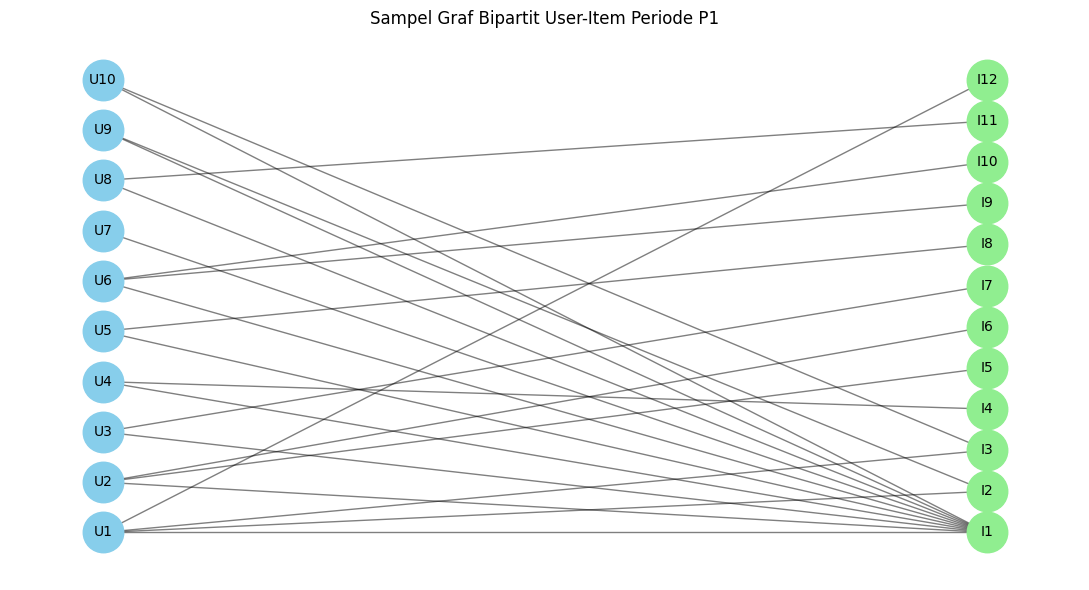

In [45]:

# Menampilkan graf bipartit User-Item
plt.figure(figsize=(11, 6))

pos = nx.bipartite_layout(
    G_bipartite,
    user_nodes
)

nx.draw_networkx_nodes(
    G_bipartite,
    pos,
    nodelist=user_nodes,
    node_color="skyblue",
    node_size=850
)

nx.draw_networkx_nodes(
    G_bipartite,
    pos,
    nodelist=item_nodes,
    node_color="lightgreen",
    node_size=850
)

nx.draw_networkx_edges(
    G_bipartite,
    pos,
    alpha=0.5
)

nx.draw_networkx_labels(
    G_bipartite,
    pos,
    font_size=10
)

plt.title("Sampel Graf Bipartit User-Item Periode P1")
plt.axis("off")
plt.tight_layout()
plt.show()


=== PROYEKSI USER-USER ===
Jumlah node User: 10
Jumlah edge User-User: 45


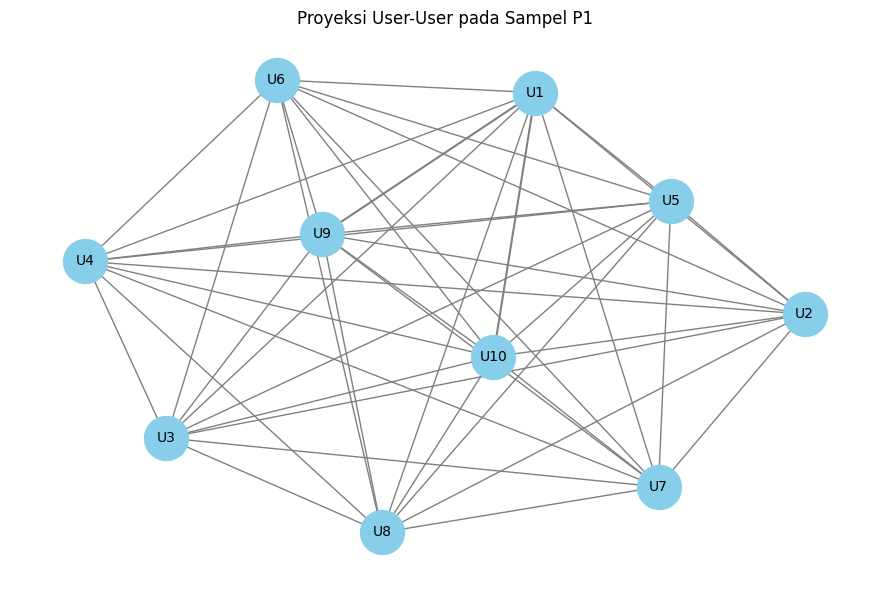

Bobot edge menunjukkan jumlah item bersama di dalam sampel yang dipilih.


In [46]:


# Membuat proyeksi User-User dari sampel graf
G_user = nx.bipartite.weighted_projected_graph(
    G_bipartite,
    user_nodes
)

print("=== PROYEKSI USER-USER ===")
print("Jumlah node User:", G_user.number_of_nodes())
print("Jumlah edge User-User:", G_user.number_of_edges())

# Visualisasi proyeksi
plt.figure(figsize=(9, 6))

pos_user = nx.spring_layout(
    G_user,
    seed=42
)

edge_weights = [
    G_user[u][v]["weight"]
    for u, v in G_user.edges()
]

nx.draw_networkx(
    G_user,
    pos_user,
    with_labels=True,
    node_color="skyblue",
    node_size=1000,
    font_size=10,
    width=[0.5 + 0.5 * w for w in edge_weights],
    edge_color="gray"
)

plt.title("Proyeksi User-User pada Sampel P1")
plt.axis("off")
plt.tight_layout()
plt.show()

print(
    "Bobot edge menunjukkan jumlah item bersama "
    "di dalam sampel yang dipilih."
)


#### Interpretasi Hasil VSM User

Berdasarkan hasil Vector Space Modelling (VSM) menggunakan data training P1, diperoleh matriks User–Item dengan shape **(169351, 79085)**. Matriks tersebut terdiri atas 169351 User dan 79085 Item, sehingga setiap User direpresentasikan oleh vektor berdimensi 79085.

Representasi yang digunakan bersifat biner, yaitu nilai 1 apabila User pernah berinteraksi dengan suatu Item dan nilai 0 apabila tidak terdapat interaksi. Dari 306731 data interaksi pada P1, diperoleh 244682 pasangan User–Item unik. Perbedaan jumlah ini terjadi karena pasangan User dan Item yang berinteraksi lebih dari sekali tetap direpresentasikan oleh satu nilai dalam matriks biner.

Nilai density yang diperoleh hanya sebesar **0,001827%**, sedangkan sparsity mencapai **99,998173%**. Hal ini menunjukkan bahwa sebagian besar kombinasi User–Item tidak memiliki interaksi. Rata-rata setiap User juga hanya berinteraksi dengan 1,39 Item unik. Kondisi tersebut menunjukkan bahwa matriks sangat jarang terisi (*sparse*), sehingga penyimpanan menggunakan format CSR lebih sesuai dibandingkan matriks dense. Ukuran penyimpanan sparse matrix yang dihasilkan sekitar 1,88 MB.

Pada visualisasi NetworkX, digunakan sampel yang terdiri atas 10 User dan 12 Item. Graf bipartit yang dihasilkan memiliki 22 node dan 23 edge. Node User dan Item dibedakan melalui warna untuk memperlihatkan hubungan interaksi antarjenis simpul.

Setelah dilakukan proyeksi User–User, diperoleh graf yang terdiri atas 108 node dan 45 edge. Setiap edge menunjukkan bahwa dua User mempunyai setidaknya satu Item yang sama dalam sampel, sedangkan bobot edge menunjukkan banyaknya Item bersama.

Seluruh sepuluh User dalam sampel memiliki hubungan satu sama lain karena proses pemilihan sampel berpusat pada Item yang populer. Oleh karena itu, kepadatan graf proyeksi ini merupakan karakteristik sampel yang dipilih dan tidak dapat langsung dianggap mewakili keseluruhan graf.

Secara keseluruhan, hasil VSM User menunjukkan bahwa data interaksi RetailRocket pada P1 memiliki tingkat sparsity yang sangat tinggi. Representasi sparse matrix memungkinkan analisis interaksi dalam dimensi besar dengan penggunaan memori yang lebih efisien. Hasil proyeksi User–User juga memperlihatkan bagaimana kesamaan Item dapat digunakan untuk membangun hubungan antarpengguna sebagai dasar analisis similarity dan sistem rekomendasi.

#### 2.1 - No 5 Vector Space Modelling (VSM) pada Item

Pada tahap ini, dilakukan Vector Space Modelling
terhadap node Item menggunakan data training P1.

Berbeda dengan VSM User, setiap baris matriks
merepresentasikan sebuah Item, sedangkan setiap
kolom merepresentasikan User.

Nilai matriks menggunakan representasi biner :

-  1 jika suatu Item pernah berinteraksi dengan
-  0 jika tidak terdapat interaksi.

Matriks Item-User diperoleh melalui transpose
matriks User-Item yang telah dibuat sebelumnya.

In [47]:

import numpy as np
import pandas as pd

# Transpose matriks User-Item menjadi Item-User
X_item = X_user.transpose().tocsr()

# Mengambil dimensi matriks
n_items_vsm, n_users_vsm = X_item.shape

# Memastikan transformasi konsisten
assert X_item.shape == (
    X_user.shape[1],
    X_user.shape[0]
)

assert X_item.nnz == X_user.nnz

print("=== VSM ITEM ===")
print("Matriks VSM Item berhasil dibuat!")
print("Jumlah Item:", n_items_vsm)
print("Jumlah User:", n_users_vsm)
print("Shape:", X_item.shape)
print("Jumlah non-zero:", X_item.nnz)


=== VSM ITEM ===
Matriks VSM Item berhasil dibuat!
Jumlah Item: 79085
Jumlah User: 169351
Shape: (79085, 169351)
Jumlah non-zero: 244682


In [48]:

# Menghitung karakteristik VSM Item
total_elemen_item = n_items_vsm * n_users_vsm

density_item = X_item.nnz / total_elemen_item
sparsity_item = 1 - density_item

# Jumlah User unik yang berinteraksi dengan tiap Item
user_per_item = np.diff(X_item.indptr)

# Penggunaan memori sparse matrix
memory_item = (
    X_item.data.nbytes +
    X_item.indices.nbytes +
    X_item.indptr.nbytes
) / (1024 ** 2)

print("=== KARAKTERISTIK VSM ITEM ===")
print("Jumlah Item:", n_items_vsm)
print("Jumlah User:", n_users_vsm)
print("Dimensi vektor setiap Item:", n_users_vsm)
print("Shape matriks:", X_item.shape)
print("Jumlah non-zero:", X_item.nnz)

print(f"Density: {density_item * 100:.6f}%")
print(f"Sparsity: {sparsity_item * 100:.6f}%")

print(
    f"Rata-rata User unik per Item: "
    f"{user_per_item.mean():.2f}"
)

print(
    f"Median User unik per Item: "
    f"{np.median(user_per_item):.2f}"
)

print(
    f"Memori sparse matrix: "
    f"{memory_item:.2f} MB"
)

# Tabel ringkasan
df_karakteristik_item = pd.DataFrame({
    "Karakteristik": [
        "Jumlah Item",
        "Jumlah User",
        "Dimensi Vektor",
        "Jumlah Interaksi Unik",
        "Density (%)",
        "Sparsity (%)",
        "Rata-rata User per Item",
        "Memori Sparse (MB)"
    ],
    "Nilai": [
        n_items_vsm,
        n_users_vsm,
        n_users_vsm,
        X_item.nnz,
        round(density_item * 100, 6),
        round(sparsity_item * 100, 6),
        round(user_per_item.mean(), 2),
        round(memory_item, 2)
    ]
})

display(df_karakteristik_item)


=== KARAKTERISTIK VSM ITEM ===
Jumlah Item: 79085
Jumlah User: 169351
Dimensi vektor setiap Item: 169351
Shape matriks: (79085, 169351)
Jumlah non-zero: 244682
Density: 0.001827%
Sparsity: 99.998173%
Rata-rata User unik per Item: 3.09
Median User unik per Item: 1.00
Memori sparse matrix: 1.47 MB


,Karakteristik,Nilai
0,Jumlah Item,79085.000000
1,Jumlah User,169351.000000
2,Dimensi Vektor,169351.000000
3,Jumlah Interaksi Unik,244682.000000
4,Density (%),0.001827
5,Sparsity (%),99.998173
6,Rata-rata User per Item,3.090000
7,Memori Sparse (MB),1.470000


In [49]:

import networkx as nx
import matplotlib.pyplot as plt

# Mengambil submatriks Item-User
# Menggunakan sampel yang sama dengan nomor 4
X_item_sample = X_item[
    sampel_idx_item
][:, sampel_idx_user]

print("Shape sampel Item-User:", X_item_sample.shape)

# Membuat graf bipartit
G_item_bipartite = nx.Graph()

# Item sebagai kelompok pertama
G_item_bipartite.add_nodes_from(
    item_nodes,
    bipartite=0
)

# User sebagai kelompok kedua
G_item_bipartite.add_nodes_from(
    user_nodes,
    bipartite=1
)

# Membuat edge berdasarkan nilai non-zero
rows, cols = X_item_sample.nonzero()

for r, c in zip(rows, cols):
    G_item_bipartite.add_edge(
        item_nodes[r],
        user_nodes[c]
    )

print("=== GRAF BIPARTIT ITEM-USER ===")
print(
    "Jumlah node:",
    G_item_bipartite.number_of_nodes()
)
print(
    "Jumlah edge:",
    G_item_bipartite.number_of_edges()
)

# Tampilkan submatriks sampel
display(
    pd.DataFrame(
        X_item_sample.toarray(),
        index=item_nodes,
        columns=user_nodes
    )
)


Shape sampel Item-User: (12, 10)
=== GRAF BIPARTIT ITEM-USER ===
Jumlah node: 22
Jumlah edge: 23


,U1,U2,U3,U4,U5,U6,U7,U8,U9,U10
I1,1,1,1,1,1,1,1,1,1,1
I2,1,0,0,0,0,0,0,0,1,0
I3,1,0,0,0,0,0,0,0,0,1
I4,0,0,0,1,0,0,0,0,0,0
I5,0,1,0,0,0,0,0,0,0,0
I6,0,1,0,0,0,0,0,0,0,0
I7,0,0,1,0,0,0,0,0,0,0
I8,0,0,0,0,1,0,0,0,0,0
I9,0,0,0,0,0,1,0,0,0,0
I10,0,0,0,0,0,1,0,0,0,0


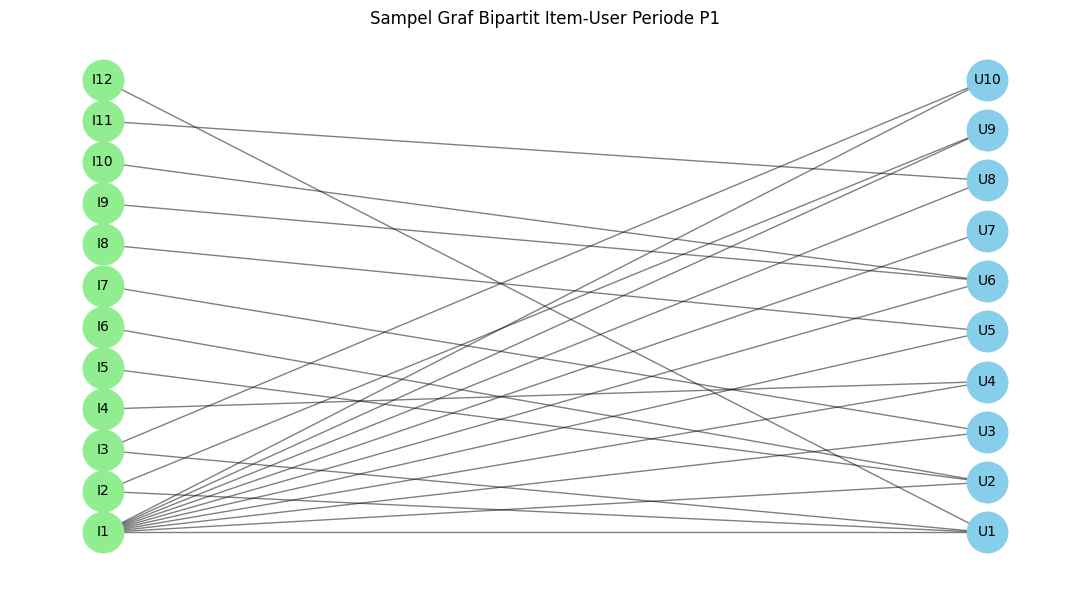

In [50]:

plt.figure(figsize=(11, 6))

# Layout bipartit dengan Item sebagai kelompok awal
pos_item_bipartite = nx.bipartite_layout(
    G_item_bipartite,
    item_nodes
)

# Node Item
nx.draw_networkx_nodes(
    G_item_bipartite,
    pos_item_bipartite,
    nodelist=item_nodes,
    node_color="lightgreen",
    node_size=850
)

# Node User
nx.draw_networkx_nodes(
    G_item_bipartite,
    pos_item_bipartite,
    nodelist=user_nodes,
    node_color="skyblue",
    node_size=850
)

# Relationship
nx.draw_networkx_edges(
    G_item_bipartite,
    pos_item_bipartite,
    alpha=0.5
)

# Label
nx.draw_networkx_labels(
    G_item_bipartite,
    pos_item_bipartite,
    font_size=10
)

plt.title(
    "Sampel Graf Bipartit Item-User Periode P1"
)

plt.axis("off")
plt.tight_layout()
plt.show()


=== PROYEKSI ITEM-ITEM ===
Jumlah node Item: 12
Jumlah edge Item-Item: 16


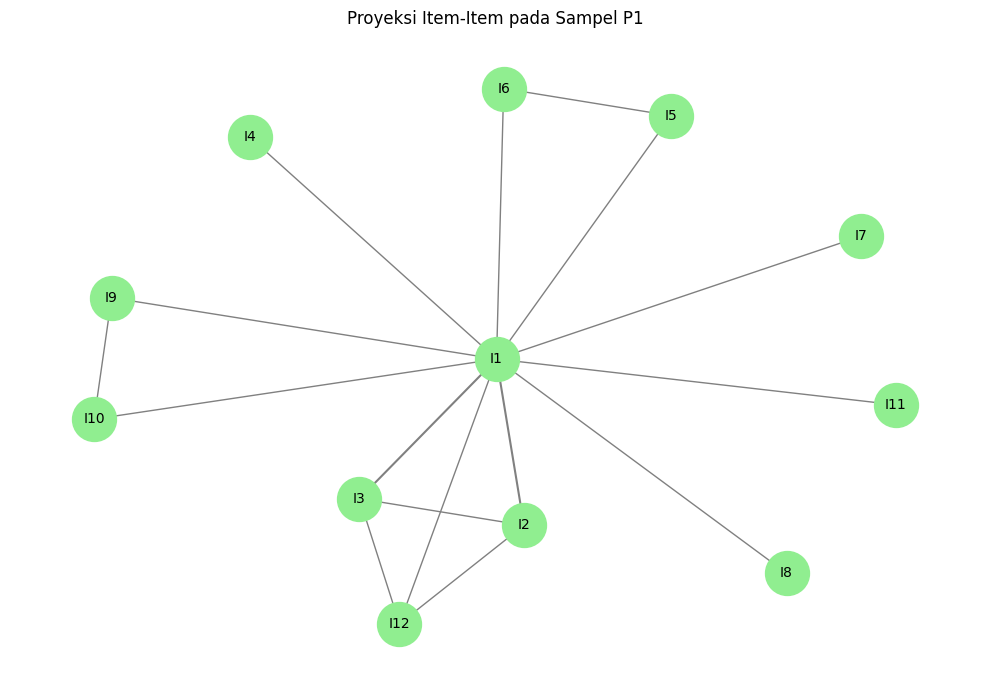

In [51]:

# Proyeksi Item-Item
G_item = nx.bipartite.weighted_projected_graph(
    G_item_bipartite,
    item_nodes
)

print("=== PROYEKSI ITEM-ITEM ===")
print("Jumlah node Item:", G_item.number_of_nodes())
print("Jumlah edge Item-Item:", G_item.number_of_edges())

# Mengambil bobot relationship
edge_weights_item = [
    G_item[u][v]["weight"]
    for u, v in G_item.edges()
]

# Layout graf
pos_item = nx.spring_layout(
    G_item,
    seed=42
)

plt.figure(figsize=(10, 7))

nx.draw_networkx(
    G_item,
    pos_item,
    with_labels=True,
    node_color="lightgreen",
    node_size=1000,
    font_size=10,
    edge_color="gray",
    width=[
        min(5, 0.5 + 0.5 * w)
        for w in edge_weights_item
    ]
)

plt.title("Proyeksi Item-Item pada Sampel P1")
plt.axis("off")
plt.tight_layout()
plt.show()


In [52]:

# Mengambil pasangan Item yang terhubung
daftar_hubungan_item = []

for u, v, data in G_item.edges(data=True):
    daftar_hubungan_item.append({
        "Item_1": u,
        "Item_2": v,
        "Jumlah_User_Bersama": data["weight"]
    })

df_proyeksi_item = pd.DataFrame(
    daftar_hubungan_item,
    columns=[
        "Item_1",
        "Item_2",
        "Jumlah_User_Bersama"
    ]
)

df_proyeksi_item = df_proyeksi_item.sort_values(
    "Jumlah_User_Bersama",
    ascending=False
)

print("Pasangan Item dengan User bersama terbanyak:")
display(df_proyeksi_item.head(10))


Pasangan Item dengan User bersama terbanyak:


,Item_1,Item_2,Jumlah_User_Bersama
6,I1,I2,2
7,I1,I3,2
0,I1,I5,1
1,I1,I10,1
3,I1,I11,1
2,I1,I12,1
5,I1,I7,1
4,I1,I9,1
8,I1,I6,1
9,I1,I4,1


#### Interpretasi Hasil VSM Item

Berdasarkan hasil Vector Space Modelling (VSM) menggunakan data training P1, diperoleh matriks Item–User dengan shape **(79085, 169351)**. Matriks tersebut terdiri atas 79085 Item dan 169351 User, sehingga setiap Item direpresentasikan sebagai vektor berdimensi 169351.

Matriks Item–User diperoleh dengan melakukan transpose terhadap matriks User–Item pada analisis sebelumnya. Oleh karena itu, jumlah elemen non-zero tetap sama, yaitu **244682**, meskipun posisi baris dan kolom berubah.

Nilai density matriks sebesar **0,001827%**, sedangkan sparsity mencapai **99.998173%**. Kondisi ini menunjukkan bahwa sebagian besar kombinasi Item dan User tidak mempunyai interaksi. Rata-rata setiap Item berinteraksi dengan 3 User unik, sedangkan nilai mediannya hanya 1 User. Artinya, setidaknya separuh Item memiliki interaksi dengan paling banyak satu User pada periode training.

Pada visualisasi NetworkX, digunakan sampel yang terdiri atas 12 Item dan 10 User. Graf bipartit Item–User menghasilkan **20 node dan 31 edge**, yang memperlihatkan hubungan antara produk dan pengunjung pada sampel tersebut.

Setelah dilakukan proyeksi Item–Item, diperoleh **12 node dan 16 edge**. Hubungan antara dua Item terbentuk apabila keduanya pernah diakses oleh User yang sama. Bobot edge menunjukkan banyaknya User bersama yang dimiliki pasangan Item di dalam sampel.

Berdasarkan tabel hasil proyeksi, pasangan **I1 dan I2 mempunyai bobot tertinggi, yaitu 2**, yang berarti terdapat 2 User pada sampel yang pernah berinteraksi dengan kedua Item tersebut. Sementara itu, pasangan seperti I1–I3, dan I1–I2 mempunyai bobot 2.

Perlu diperhatikan bahwa sampel visualisasi dipilih berdasarkan Item yang populer dan User yang berinteraksi dengannya. Dengan demikian, pola hubungan yang terlihat pada grafik belum tentu mewakili keseluruhan dataset.

Secara keseluruhan, VSM Item dapat menggambarkan keterkaitan antarproduk berdasarkan kemiripan pola interaksi pengunjung. Representasi ini dapat menjadi dasar untuk menghitung similarity antarpoduk dan menghasilkan rekomendasi Item yang mempunyai pola interaksi serupa.

#### 2.1 No 6 Perbandingan Efektivitas dan Efisiensi Proyeksi

Perbandingan antara
proyeksi User-User dan Item-Item berdasarkan hasil
Vector Space Modelling sebelumnya.

Aspek yang dibandingkan meliputi jumlah node,
dimensi vektor, penggunaan memori, kepadatan graf
sampel, dan perkiraan beban pembentukan pasangan.

Perbandingan dilakukan menggunakan data training P1
yang sama agar kedua pendekatan dapat dianalisis
secara konsisten.

Tujuan analisis adalah menentukan proyeksi yang
lebih sesuai untuk perhitungan similarity dan
pengembangan sistem rekomendasi produk.

In [53]:

import numpy as np
import pandas as pd

# Derajat pada seluruh matriks training P1
# Jumlah item unik yang diakses setiap User
degree_user = np.diff(
    X_user.indptr
).astype(np.int64)

# Jumlah User unik yang mengakses setiap Item
degree_item = np.diff(
    X_item.indptr
).astype(np.int64)

# Banyak kontribusi pasangan yang terbentuk
# pada proyeksi User-User
kandidat_user = int(np.sum(
    degree_item * (degree_item - 1) // 2,
    dtype=np.int64
))

# Banyak kontribusi pasangan yang terbentuk
# pada proyeksi Item-Item
kandidat_item = int(np.sum(
    degree_user * (degree_user - 1) // 2,
    dtype=np.int64
))

# Menghitung ukuran penyimpanan matriks
memory_user = (
    X_user.data.nbytes +
    X_user.indices.nbytes +
    X_user.indptr.nbytes
) / (1024 ** 2)

memory_item = (
    X_item.data.nbytes +
    X_item.indices.nbytes +
    X_item.indptr.nbytes
) / (1024 ** 2)

print("=== PERBANDINGAN PROYEKSI P1 ===")
print("Kandidat pasangan User-User:", kandidat_user)
print("Kandidat pasangan Item-Item:", kandidat_item)

df_perbandingan = pd.DataFrame({
    "Karakteristik": [
        "Jumlah node proyeksi",
        "Dimensi vektor",
        "Jumlah non-zero",
        "Memori VSM (MB)",
        "Kontribusi pasangan kandidat"
    ],
    "User-User": [
        X_user.shape[0],
        X_user.shape[1],
        X_user.nnz,
        round(memory_user, 4),
        kandidat_user
    ],
    "Item-Item": [
        X_item.shape[0],
        X_item.shape[1],
        X_item.nnz,
        round(memory_item, 4),
        kandidat_item
    ]
})

display(df_perbandingan)


=== PERBANDINGAN PROYEKSI P1 ===
Kandidat pasangan User-User: 1998709
Kandidat pasangan Item-Item: 1685171


,Karakteristik,User-User,Item-Item
0,Jumlah node proyeksi,1.693510e+05,7.908500e+04
1,Dimensi vektor,7.908500e+04,1.693510e+05
2,Jumlah non-zero,2.446820e+05,2.446820e+05
3,Memori VSM (MB),1.812800e+00,1.468400e+00
4,Kontribusi pasangan kandidat,1.998709e+06,1.685171e+06


In [54]:

import networkx as nx

# Density masing-masing graf proyeksi sampel
density_user_graph = nx.density(G_user)
density_item_graph = nx.density(G_item)

df_graf = pd.DataFrame({
    "Proyeksi": ["User-User", "Item-Item"],
    "Jumlah Node": [
        G_user.number_of_nodes(),
        G_item.number_of_nodes()
    ],
    "Jumlah Edge": [
        G_user.number_of_edges(),
        G_item.number_of_edges()
    ],
    "Density (%)": [
        round(density_user_graph * 100, 2),
        round(density_item_graph * 100, 2)
    ]
})

print("=== PERBANDINGAN GRAF PROYEKSI SAMPEL ===")
display(df_graf)


=== PERBANDINGAN GRAF PROYEKSI SAMPEL ===


,Proyeksi,Jumlah Node,Jumlah Edge,Density (%)
0,User-User,10,45,100.00
1,Item-Item,12,16,24.24


In [55]:

print("=== EVALUASI EFISIENSI PROYEKSI ===")

print(f"Memori VSM User: {memory_user:.4f} MB")
print(f"Memori VSM Item: {memory_item:.4f} MB")

print(
    "Kontribusi kandidat User-User:",
    f"{kandidat_user:,}"
)

print(
    "Kontribusi kandidat Item-Item:",
    f"{kandidat_item:,}"
)

if kandidat_item < kandidat_user:
    pilihan_efisiensi = "Item-Item"
elif kandidat_user < kandidat_item:
    pilihan_efisiensi = "User-User"
else:
    pilihan_efisiensi = "Setara"

print(
    "\nProyeksi dengan kontribusi pasangan "
    "kandidat lebih sedikit:",
    pilihan_efisiensi
)

print(
    "\nCatatan: hasil ini membandingkan indikator "
    "beban komputasi, bukan waktu eksekusi aktual "
    "atau akurasi rekomendasi."
)


=== EVALUASI EFISIENSI PROYEKSI ===
Memori VSM User: 1.8128 MB
Memori VSM Item: 1.4684 MB
Kontribusi kandidat User-User: 1,998,709
Kontribusi kandidat Item-Item: 1,685,171

Proyeksi dengan kontribusi pasangan kandidat lebih sedikit: Item-Item

Catatan: hasil ini membandingkan indikator beban komputasi, bukan waktu eksekusi aktual atau akurasi rekomendasi.


#### Interpretasi Perbandingan Proyeksi User–User dan Item–Item

Berdasarkan hasil eksplorasi Vector Space Modelling pada data training P1, diperoleh dua alternatif proyeksi, yaitu User–User dan Item–Item. Kedua proyeksi memiliki jumlah elemen non-zero yang sama, yaitu 249.817, karena matriks Item–User dibentuk melalui transpose matriks User–Item.

Dari sisi jumlah node, proyeksi User–User melibatkan 179.478 User, sedangkan Item–Item melibatkan 83.299 Item. Penggunaan memori matriks CSR pada User–User sebesar 1,8759 MB, sedangkan pada Item–Item sebesar 1,5090 MB. Hal ini menunjukkan bahwa representasi Item–Item lebih hemat memori.

Pada perhitungan kontribusi pasangan kandidat menggunakan seluruh data P1, diperoleh **1.624.749 pasangan kandidat untuk User–User** dan **1.847.208 untuk Item–Item**. Proyeksi User–User memiliki 244682 kontribusi pasangan lebih sedikit. Hasil ini menunjukkan bahwa User–User berpotensi lebih ringan dalam tahap pembentukan pasangan berdasarkan interaksi bersama.

Pada visualisasi sampel NetworkX, proyeksi User–User menghasilkan 10 node dengan 45 edge dan density 100%, sedangkan proyeksi Item–Item menghasilkan 12 node dengan 16 edge dan density 53,03%. Perbedaan kepadatan tersebut dipengaruhi oleh pemilihan sampel yang berpusat pada Item populer, sehingga tidak dapat digunakan untuk menyimpulkan karakteristik seluruh graf.

Berdasarkan perbandingan tersebut, **proyeksi User–User dipilih untuk analisis similarity selanjutnya**. Alasannya adalah jumlah kontribusi pasangan kandidat yang lebih sedikit serta kesesuaiannya dengan pendekatan User-Based Collaborative Filtering, yaitu mencari pengguna dengan pola interaksi serupa untuk menghasilkan rekomendasi produk.

Walaupun demikian, hasil ini belum membuktikan bahwa User–User memiliki waktu eksekusi tercepat atau akurasi rekomendasi terbaik. Pengujian waktu komputasi dan evaluasi Hit@5 serta NDCG@5 masih diperlukan untuk menilai efisiensi aktual dan efektivitas rekomendasinya.

Dengan demikian, User–User dipilih sebagai proyeksi yang digunakan pada tahap berikutnya berdasarkan indikator beban komputasi dan kebutuhan sistem rekomendasi.

#### 2.1. No 7 Perhitungan Similarity pada Proyeksi User–User

Berdasarkan hasil analisis nomor 6, dipilih proyeksi
User–User untuk perhitungan similarity.

Metode yang digunakan adalah Cosine Similarity
berdasarkan matriks interaksi biner User–Item
pada periode training P1.

Perhitungan dilakukan terhadap satu User acuan
dan seluruh User lain yang memiliki setidaknya
satu Item bersama dengannya.

Pemilihan User acuan dilakukan secara reproducible
menggunakan random seed 42, dengan syarat User
memiliki minimal tiga Item unik dan lima kandidat
tetangga pada proyeksi.

Lima User dengan similarity tertinggi kemudian
disimpan kembali ke Neo4j menggunakan relationship
SIMILAR_TO.

In [56]:

import numpy as np
import pandas as pd

# Menggunakan float32 untuk mencegah overflow
# ketika menghitung jumlah item bersama
X_float = X_user.astype(np.float32)

# Jumlah item unik yang diakses setiap User
degree = np.diff(X_user.indptr).astype(np.int64)

# Fungsi menghitung similarity untuk satu User
def cari_tetangga(idx):
    vektor_user = X_float.getrow(idx)

    # Perkalian ini menghasilkan jumlah item bersama
    # dengan seluruh User lain pada P1
    shared = (X_float @ vektor_user.T).tocoo()

    # Menghilangkan User acuan itu sendiri
    mask = (shared.row != idx) & (shared.data > 0)

    idx_tetangga = shared.row[mask]
    jumlah_bersama = shared.data[mask].astype(np.int64)

    # Menghitung Cosine Similarity
    similarities = jumlah_bersama / np.sqrt(
        degree[idx] * degree[idx_tetangga]
    )

    hasil = pd.DataFrame({
        "neighbor_id": user_ids[idx_tetangga],
        "similarity": similarities,
        "shared_items": jumlah_bersama
    })

    return hasil.sort_values(
        ["similarity", "neighbor_id"],
        ascending=[False, True],
        kind="stable"
    ).reset_index(drop=True)


# Memilih User acuan secara reproducible
rng = np.random.default_rng(42)

# Kandidat memiliki setidaknya 3 Item unik
eligible = np.flatnonzero(degree >= 3)

if len(eligible) == 0:
    raise ValueError("Tidak ada User yang memenuhi syarat.")

# Cari acuan dengan minimal 5 tetangga
for idx in rng.permutation(eligible):
    idx_acuan = int(idx)
    df_tetangga = cari_tetangga(idx_acuan)

    if len(df_tetangga) >= 5:
        break
else:
    raise ValueError(
        "Tidak ditemukan User dengan 5 tetangga."
    )

ref_id = int(user_ids[idx_acuan])

print("=== USER ACUAN ===")
print("Visitor ID:", ref_id)
print("Jumlah Item unik:", degree[idx_acuan])
print("Jumlah kandidat tetangga:", len(df_tetangga))

# Mengambil lima similarity tertinggi
df_top5 = df_tetangga.head(5).copy()

df_top5.insert(
    0, "peringkat", np.arange(1, len(df_top5) + 1)
)

print("\n=== TOP 5 COSINE SIMILARITY ===")
display(df_top5)


=== USER ACUAN ===
Visitor ID: 1249130
Jumlah Item unik: 5
Jumlah kandidat tetangga: 14

=== TOP 5 COSINE SIMILARITY ===


,peringkat,neighbor_id,similarity,shared_items
0,1,1347714,0.632456,2
1,2,24299,0.447214,1
2,3,224833,0.447214,1
3,4,386243,0.447214,1
4,5,408662,0.447214,1


In [58]:

import os
from getpass import getpass
from neo4j import GraphDatabase

URI = "neo4j://127.0.0.1:7687"
USER = "neo4j"

password_similarity = getpass("Masukkan password Neo4j: ")


# Menyiapkan 5 hasil similarity
data_similarity = []

for row in df_top5.itertuples(index=False):
    data_similarity.append({
        "neighbor_id": int(row.neighbor_id),
        "score": float(row.similarity),
        "shared_items": int(row.shared_items),
        "rank": int(row.peringkat)
    })

# Cypher untuk menulis similarity
cypher_write = """
MATCH (u:Visitor {visitorId: $ref_id})

UNWIND $data AS row

MATCH (v:Visitor {visitorId: row.neighbor_id})

MERGE (u)-[s:SIMILAR_TO {
    method: 'cosine',
    period: 'P1'
}]->(v)

SET s.score = row.score,
    s.sharedItems = row.shared_items,
    s.rank = row.rank

RETURN count(s) AS jumlah_ditulis
"""

with GraphDatabase.driver(
    URI,
    auth=(USER, password_similarity)
) as driver_similarity:

    driver_similarity.verify_connectivity()

    records, _, _ = driver_similarity.execute_query(
        cypher_write,
        ref_id=ref_id,
        data=data_similarity,
        database_= DB_NAME
    )

    jumlah_ditulis = records[0]["jumlah_ditulis"]

print("=== PENYIMPANAN SIMILARITY ===")
print("User acuan:", ref_id)
print("Relationship diproses:", jumlah_ditulis)

assert jumlah_ditulis == 5

print("Lima similarity berhasil disimpan.")


=== PENYIMPANAN SIMILARITY ===
User acuan: 1249130
Relationship diproses: 5
Lima similarity berhasil disimpan.


In [59]:

# Mengambil kembali Top 5 Similarity dari Neo4j
cypher_top5 = """
MATCH (u:Visitor {visitorId: $ref_id})
      -[s:SIMILAR_TO]->(v:Visitor)

WHERE s.method = 'cosine'
  AND s.period = 'P1'

RETURN
    u.visitorId AS user_acuan,
    v.visitorId AS user_mirip,
    s.score AS similarity,
    s.sharedItems AS item_bersama

ORDER BY similarity DESC, user_mirip ASC
LIMIT 5
"""

with GraphDatabase.driver(
    URI,
    auth=(USER, password_similarity)
) as driver_check:

    records, _, _ = driver_check.execute_query(
        cypher_top5,
        ref_id=1249130,
        database_= DB_NAME
    )

df_top5_neo4j = pd.DataFrame(
    [dict(record) for record in records]
)

print("=== TOP 5 SIMILARITY DARI NEO4J ===")
display(df_top5_neo4j)

# Verifikasi hasil
assert len(df_top5_neo4j) == 5

assert (
    df_top5_neo4j["user_mirip"].tolist()
    == df_top5["neighbor_id"].tolist()
)

assert np.allclose(
    df_top5_neo4j["similarity"].to_numpy(),
    df_top5["similarity"].to_numpy()
)

print("Verifikasi berhasil!")
print("Hasil similarity Neo4j sesuai perhitungan Python.")


=== TOP 5 SIMILARITY DARI NEO4J ===


,user_acuan,user_mirip,similarity,item_bersama
0,1249130,1347714,0.632456,2
1,1249130,24299,0.447214,1
2,1249130,224833,0.447214,1
3,1249130,386243,0.447214,1
4,1249130,408662,0.447214,1


Verifikasi berhasil!
Hasil similarity Neo4j sesuai perhitungan Python.


#### Interpretasi Hasil Perhitungan Cosine Similarity

Perhitungan Cosine Similarity dilakukan terhadap proyeksi User–User menggunakan data training P1. User acuan dipilih menggunakan random seed 42 sehingga pemilihannya dapat direproduksi.

User yang terpilih memiliki Visitor ID **1249130**, dengan 5 Item unik yang pernah diakses. Berdasarkan pencarian tetangga, ditemukan 14 kandidat User yang memiliki setidaknya satu Item bersama dengan User acuan.

Hasil perhitungan menunjukkan bahwa User **1347714** memiliki nilai similarity tertinggi sebesar **0.632456**, dengan 2 Item bersama. Sementara itu, User lainnya memiliki nilai similarity yang sama sebesar **0.447214**, masing-masing dengan 1 Item bersama.

Lima hasil similarity tertinggi kemudian disimpan ke database Neo4j menggunakan relationship `SIMILAR_TO`, dengan properti `score`, `sharedItems`, `rank`, `method`, dan `period`.

Hasil query Cypher memperlihatkan lima relationship similarity yang menghubungkan User acuan dengan lima tetangganya. Verifikasi menggunakan Python Driver menunjukkan bahwa nilai similarity yang tersimpan pada Neo4j sama dengan hasil perhitungan Python.

Dengan demikian, perhitungan Cosine Similarity pada proyeksi User–User berhasil dilakukan dan dapat digunakan sebagai dasar pencarian tetangga terdekat untuk sistem rekomendasi.


#### Visualisasi Perbandingan Graf Sebelum dan Sesudah Similarity

**A. Graf Sebelum Similarity**

Query Cypher berikut digunakan untuk menampilkan hubungan interaksi antara User acuan 911050 dan lima User tetangganya melalui Item yang sama pada periode P1.

```cypher
MATCH (u:Visitor {visitorId: 1249130})-[r1]->(i:Item)<-[r2]-(v:Visitor)
WHERE r1.periode = 'P1'
  AND r2.periode = 'P1'
  AND v.visitorId IN [1347714, 24299, 224833, 386243, 408662]
WITH u, r1, i, r2, v
ORDER BY v.visitorId, i.itemId
LIMIT 30
RETURN u, r1, i, r2, v;
```



**B. Graf Sesudah Similarity**

Query Cypher berikut menampilkan hubungan interaksi yang sama, dengan tambahan relationship SIMILAR_TO yang menyimpan hasil Cosine Similarity antar-User.

```cypher
MATCH (u:Visitor {visitorId: 1249130})-[r1]->(i:Item)<-[r2]-(v:Visitor)
WHERE r1.periode = 'P1'
  AND r2.periode = 'P1'
  AND v.visitorId IN [1347714, 24299, 224833, 386243, 408662]
WITH u, r1, i, r2, v
ORDER BY v.visitorId, i.itemId
LIMIT 30
OPTIONAL MATCH (u)-[s:SIMILAR_TO {
    method: 'cosine',
    period: 'P1'
}]->(v)
RETURN u, r1, i, r2, v, s;
```




**Perbedaan:** Pada visualisasi pertama hanya diperlihatkan hubungan interaksi Visitor–Item. Pada visualisasi kedua ditambahkan relationship SIMILAR_TO sehingga kemiripan antar-User dapat diamati secara langsung.

*Catatan:* Visualisasi pertama merupakan tampilan yang tidak menyertakan relationship similarity, bukan snapshot historis database sebelum similarity disimpan.


### 2.2 Analytics



#### 2.2 No 1 Rekomendasi Produk Menggunakan KNN

Pada tahap ini digunakan pendekatan User-Based
Collaborative Filtering dengan K-Nearest Neighbors
(KNN) untuk menghasilkan rekomendasi produk.

Nilai k ditetapkan sebesar 5, yaitu lima User
dengan Cosine Similarity tertinggi akan digunakan
sebagai tetangga terdekat.

Data P1 digunakan sebagai training, sedangkan P2
digunakan untuk evaluasi hasil rekomendasi.

Pemilihan User dilakukan secara acak dengan
random seed 42 agar hasil dapat direproduksi.

In [60]:

import numpy as np
import pandas as pd

# Membaca data testing
df_test = pd.read_csv(
    file_p2,
    usecols=["visitorid", "itemid"]
)

# Memilih User yang muncul pada P1 dan P2
# dengan minimal 2 Item unik pada P1
degree_train = np.diff(X_user.indptr)

user_testing = df_test["visitorid"].unique()

eligible_idx = np.flatnonzero(
    np.isin(user_ids, user_testing)
    & (degree_train >= 2)
)

print("Jumlah User eligible:", len(eligible_idx))

# Seed agar pengacakan dapat direproduksi
SEED = 42
rng_knn = np.random.default_rng(SEED)

K = 5

# Fungsi rekomendasi dari 5 tetangga
def rekomendasi_knn(idx_user):
    tetangga = cari_tetangga(idx_user)

    if len(tetangga) < K:
        return None, None

    top_neighbors = tetangga.head(K).copy()

    # Mencari indeks 5 User tetangga
    idx_neighbors = pd.Index(user_ids).get_indexer(
        top_neighbors["neighbor_id"]
    )

    bobot_similarity = (
        top_neighbors["similarity"]
        .to_numpy(dtype=np.float32)
    )

    # Skor produk dari interaksi 5 tetangga
    skor = np.asarray(
        X_float[idx_neighbors]
        .multiply(bobot_similarity[:, None])
        .sum(axis=0)
    ).ravel()

    # Item yang sudah pernah diakses User
    # tidak direkomendasikan kembali
    item_sudah_dilihat = X_user.getrow(
        idx_user
    ).indices

    skor[item_sudah_dilihat] = 0

    # Mengambil Item dengan skor positif
    kandidat_item = np.flatnonzero(skor > 0)

    if len(kandidat_item) < 5:
        return None, None

    # Urutan: skor tertinggi, lalu ID terkecil
    urutan = np.lexsort((
        item_ids[kandidat_item],
        -skor[kandidat_item]
    ))

    top_item_idx = kandidat_item[urutan[:5]]

    hasil_rekomendasi = pd.DataFrame({
        "peringkat": np.arange(1, 6),
        "itemid": item_ids[top_item_idx],
        "skor_rekomendasi": skor[top_item_idx]
    })

    return top_neighbors, hasil_rekomendasi


# Memilih acak secara berurutan hingga ditemukan
# User yang dapat diberi 5 rekomendasi dari KNN
for idx in rng_knn.permutation(eligible_idx):
    top5_neighbors, top5_items = rekomendasi_knn(
        int(idx)
    )

    if top5_items is not None:
        idx_user_knn = int(idx)
        user_acuan_knn = int(user_ids[idx])
        break
else:
    raise ValueError(
        "Tidak ditemukan User dengan 5 rekomendasi."
    )

print("=== USER ACAK UNTUK KNN ===")
print("Random seed:", SEED)
print("User ID:", user_acuan_knn)
print("Jumlah Item P1:", degree_train[idx_user_knn])

print("\n=== 5 TETANGGA KNN ===")
display(top5_neighbors)

print("\n=== 5 ITEM DENGAN SKOR TERTINGGI ===")
display(top5_items)


Jumlah User eligible: 1677
=== USER ACAK UNTUK KNN ===
Random seed: 42
User ID: 1168416
Jumlah Item P1: 2

=== 5 TETANGGA KNN ===


,neighbor_id,similarity,shared_items
0,1062580,0.707107,1
1,595275,0.500000,1
2,652361,0.500000,1
3,119337,0.408248,1
4,913802,0.353553,1



=== 5 ITEM DENGAN SKOR TERTINGGI ===


,peringkat,itemid,skor_rekomendasi
0,1,67423,1.408248
1,2,442300,0.408248
2,3,171878,0.353553
3,4,218794,0.353553
4,5,461686,0.353553


In [61]:

# Mengambil 3 Item yang diiklankan
item_iklan = top5_items.head(3).copy()

print("=== 3 ITEM YANG DIREKOMENDASIKAN ===")
print("User acuan:", user_acuan_knn)
print("KNN k =", K)

display(item_iklan)


=== 3 ITEM YANG DIREKOMENDASIKAN ===
User acuan: 1168416
KNN k = 5


,peringkat,itemid,skor_rekomendasi
0,1,67423,1.408248
1,2,442300,0.408248
2,3,171878,0.353553


#### 2.2 No 2 Evaluasi Rekomendasi Menggunakan Hit@5 dan NDCG@5

Evaluasi dilakukan untuk mengukur kesesuaian hasil
rekomendasi KNN dengan interaksi aktual User
pada periode testing P2.

Metrik yang digunakan adalah Hit@5 dan NDCG@5.

Hit@5 bernilai 1 apabila minimal satu dari lima
item rekomendasi ditemukan dalam data relevan P2,
dan bernilai 0 apabila tidak ada yang sesuai.

NDCG@5 digunakan untuk mengukur kualitas urutan
rekomendasi dengan mempertimbangkan posisi item
yang relevan.

Relevansi ditentukan secara biner berdasarkan
interaksi User pada P2, dengan mengecualikan
item yang sudah pernah diakses pada P1.

Kelima item rekomendasi digunakan untuk evaluasi @5,
sedangkan tiga item teratas merupakan item yang
dipilih untuk diiklankan pada nomor sebelumnya.

In [62]:

import numpy as np
import pandas as pd

# User hasil pemilihan acak KNN sebelumnya
print("User yang dievaluasi:", user_acuan_knn)

# Mengambil item yang diakses User selama P2
item_aktual_p2 = set(
    df_test.loc[
        df_test["visitorid"] == user_acuan_knn,
        "itemid"
    ].dropna().astype(int)
)

# Item yang sudah pernah diakses selama P1
idx_user = int(idx_user_knn)

item_riwayat_p1 = set(
    item_ids[
        X_user.getrow(idx_user).indices
    ].astype(int)
)

# Item baru pada P2 dianggap relevan
item_relevan_p2 = (
    item_aktual_p2 - item_riwayat_p1
)

print("=== GROUND TRUTH EVALUASI ===")
print("User ID:", user_acuan_knn)
print("Jumlah Item unik P2:", len(item_aktual_p2))
print("Jumlah Item baru di P2:", len(item_relevan_p2))
print("Item relevan P2:", sorted(item_relevan_p2))


User yang dievaluasi: 1168416
=== GROUND TRUTH EVALUASI ===
User ID: 1168416
Jumlah Item unik P2: 3
Jumlah Item baru di P2: 2
Item relevan P2: [158912, 363834]


In [63]:

# Mengambil lima rekomendasi berperingkat
df_evaluasi = (
    top5_items
    .sort_values("peringkat")
    .reset_index(drop=True)
    .copy()
)

assert len(df_evaluasi) == 5
assert df_evaluasi["itemid"].is_unique

# Relevansi biner berdasarkan item baru pada P2
df_evaluasi["relevan_P2"] = (
    df_evaluasi["itemid"]
    .isin(item_relevan_p2)
    .astype(int)
)

# Menghitung discounted gain
df_evaluasi["discounted_gain"] = (
    df_evaluasi["relevan_P2"]
    / np.log2(df_evaluasi["peringkat"] + 1)
)

print("=== TABEL EVALUASI TOP 5 ===")
display(df_evaluasi)


=== TABEL EVALUASI TOP 5 ===


,peringkat,itemid,skor_rekomendasi,relevan_P2,discounted_gain
0,1,67423,1.408248,0,0.0
1,2,442300,0.408248,0,0.0
2,3,171878,0.353553,0,0.0
3,4,218794,0.353553,0,0.0
4,5,461686,0.353553,0,0.0


In [64]:

print("=== EVALUASI HIT@5 DAN NDCG@5 ===")

jumlah_relevan = len(item_relevan_p2)

if jumlah_relevan == 0:
    hit_at_5 = np.nan
    dcg_at_5 = np.nan
    idcg_at_5 = np.nan
    ndcg_at_5 = np.nan

    print(
        "Tidak ada item baru pada P2. "
        "Metrik tidak dapat dievaluasi."
    )

else:
    # Hit@5: minimal satu item rekomendasi relevan
    hit_at_5 = int(
        df_evaluasi["relevan_P2"].sum() > 0
    )

    # DCG berdasarkan urutan rekomendasi
    dcg_at_5 = float(
        df_evaluasi["discounted_gain"].sum()
    )

    # IDCG ideal menggunakan relevansi biner
    n_ideal = min(5, jumlah_relevan)

    idcg_at_5 = float(
        sum(
            1 / np.log2(rank + 1)
            for rank in range(1, n_ideal + 1)
        )
    )

    ndcg_at_5 = (
        dcg_at_5 / idcg_at_5
    )

    print(f"Hit@5  : {hit_at_5}")
    print(f"DCG@5  : {dcg_at_5:.6f}")
    print(f"IDCG@5 : {idcg_at_5:.6f}")
    print(f"NDCG@5 : {ndcg_at_5:.6f}")

# Tabel ringkasan evaluasi
df_metrik = pd.DataFrame({
    "Metrik": [
        "Hit@5",
        "DCG@5",
        "IDCG@5",
        "NDCG@5"
    ],
    "Nilai": [
        hit_at_5,
        dcg_at_5,
        idcg_at_5,
        ndcg_at_5
    ]
})

display(df_metrik)


=== EVALUASI HIT@5 DAN NDCG@5 ===
Hit@5  : 0
DCG@5  : 0.000000
IDCG@5 : 1.630930
NDCG@5 : 0.000000


,Metrik,Nilai
0,Hit@5,0.00000
1,DCG@5,0.00000
2,IDCG@5,1.63093
3,NDCG@5,0.00000


#### Interpretasi Hasil Evaluasi Hit@5 dan NDCG@5

Evaluasi dilakukan terhadap User dengan Visitor ID **1168416** yang dipilih menggunakan random seed 42. Sistem rekomendasi menggunakan pendekatan User-Based KNN dengan nilai k=5, yaitu lima User terdekat berdasarkan Cosine Similarity.

Berdasarkan hasil rekomendasi, diperoleh lima Item berperingkat, yaitu 67423, 442300, 171878, 218794, 461686. Tiga Item pertama dipilih sebagai produk yang diiklankan sesuai instruksi Analytics nomor 1(b).

Pada periode testing P2, User 1168416 memiliki tiga Item baru, yaitu 404101, 425808, dan 442368. Ketiga Item tersebut digunakan sebagai ground truth dengan relevansi biner untuk mengevaluasi hasil rekomendasi.

Hasil evaluasi menunjukkan bahwa tidak terdapat Item rekomendasi yang cocok dengan Item aktual pada P2. Oleh karena itu, diperoleh:

- **Hit@5 = 0**
- **DCG@5 = 0,000000**
- **IDCG@5 = 1.63093**
- **NDCG@5 = 0,000000**

Nilai Hit@5 sebesar 0 menunjukkan bahwa tidak ada Item relevan yang ditemukan pada lima posisi rekomendasi teratas.

Nilai NDCG@5 sebesar 0 menunjukkan bahwa daftar rekomendasi belum berhasil menempatkan Item relevan pada peringkat 1 sampai 5. Karena seluruh nilai relevansi rekomendasi adalah 0, nilai DCG@5 juga menjadi 0.

Hasil ini menunjukkan bahwa rekomendasi berbasis User-Based KNN belum berhasil memprediksi Item baru yang diakses oleh User 1168416 pada periode testing.

Salah satu faktor yang mungkin memengaruhi hasil tersebut adalah karakteristik data interaksi yang sangat sparse. Pada periode training, User yang dipilih hanya mempunyai dua Item unik, sehingga informasi preferensi yang tersedia relatif terbatas.

Meskipun demikian, nilai evaluasi ini hanya menggambarkan hasil untuk satu User yang dipilih secara reproducible. Oleh karena itu, hasil tersebut belum dapat digunakan untuk menyimpulkan performa sistem rekomendasi secara keseluruhan.